# 2026-06-24 OD600 — phage infection time-course (9-9-2)

Growth/lysis curves for **9-9-2 colony (1)** challenged with two plaque-picked phages.
Readings are taken hourly, **t = 0 … 24**. Phage is spiked into each tube **once it reaches
OD600 ≈ 0.4**.

## Samples (9 total)
| column | group | bacteria | phage |
|---|---|---|---|
| `Bacteria Only` | no-phage control | 9-9-2 (1) | none |
| `P2a … P2d` | + phage #2 | 9-9-2 (1) | 9-9-2 phage #8, pick **#2** |
| `P4a … P4d` | + phage #4 | 9-9-2 (1) | 9-9-2 phage #8, pick **#4** |

- **Bacteria:** all tubes are 9-9-2, colony pick **(1)**.
- **Phage:** all from parent **9-9-2 phage #8**; `#2` and `#4` are the IDs of the two plaque
  colonies collected from it. The 4 tubes per phage (`a–d`) are treated as **replicates**.

## ⚠️ Tube pooling — from the 4:42 reading onward
Starting at the **4:42 reading (inclusive)**, the four replicate tubes per phage were **pooled
into a single tube**. From that point on each phage group is one *mix* measurement, recorded in
the group's **`a` column only**:
- `P2a` → **phage #2 mix** (pool of former P2a–d)   ·   `P2b/P2c/P2d` left blank from here on
- `P4a` → **phage #4 mix** (pool of former P4a–d)   ·   `P4b/P4c/P4d` left blank from here on

The notebook auto-detects this boundary (first row where each phage group has only its `a`
reading) and draws a green "tubes pooled" line; before it, `a–d` are genuine replicates, so the
`b/c/d` curves simply terminate at the boundary. `Bacteria Only` (control) is a single tube
throughout and is unaffected.

## How to log data (at the bench)
Fill in [`../data/assays/0624_od600_phage.csv`](../data/assays/0624_od600_phage.csv) — wide format, one row
per hour: `time` (clock time hh:mm), `t` (0–24), then one OD600 column per tube. Leave a cell
blank until that reading is taken (after pooling, only `Bacteria Only`, `P2a`, `P4a` are filled).
Re-run the notebook to refresh the plots.

> **2026-08-29 — one reading added upstream, outputs not re-run.** Digitizing **p.59** turned up a
> **t = 33** row (19:42 on 6/25 — `no Φ` 1.262, `Φ2-mix` 1.160, `Φ4-mix` 1.076) that was missing from
> `data/assays/0624_od600_phage.csv`; the CSV now has it. **The figures saved under `output/` predate
> that addition** — re-run this notebook to bring them in line. Session write-up:
> [`2026-06-24_od600-phage-infection-timecourse.md`](../lab_notebook/digitalized/2026-06-24_od600-phage-infection-timecourse.md).


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data/assays/0624_od600_phage.csv")
OUT = Path("output/0624_od600_phage")
OUT.mkdir(parents=True, exist_ok=True)

PHAGE_THRESHOLD = 0.4     # OD600 at which phage is spiked in
PHAGE_ADDED_AFTER_T = 11  # phage spiked into all tubes AFTER this reading; t>=12 = post-infection

# Tube pooling: from the 4:42 reading on, each phage group's 4 replicates were combined into one
# tube logged in its 'a' column (P2a = phage #2 mix, P4a = phage #4 mix; b/c/d left blank).
MIX_FROM_T = None  # None = auto-detect the boundary from the data; set a number to override
MIX_GROUPS = {     # phage group -> (pooled 'a' column, the b/c/d replicate columns it absorbs)
    "phage #2": ("P2a", ["P2b", "P2c", "P2d"]),
    "phage #4": ("P4a", ["P4b", "P4c", "P4d"]),
}

# Fixed experiment design — column -> metadata.
SAMPLES = pd.DataFrame([
    ("Bacteria Only", "control",  "9-9-2 (1)", "none",                   0),
    ("P2a", "phage #2", "9-9-2 (1)", "9-9-2 phage #8 pick #2", 1),
    ("P2b", "phage #2", "9-9-2 (1)", "9-9-2 phage #8 pick #2", 2),
    ("P2c", "phage #2", "9-9-2 (1)", "9-9-2 phage #8 pick #2", 3),
    ("P2d", "phage #2", "9-9-2 (1)", "9-9-2 phage #8 pick #2", 4),
    ("P4a", "phage #4", "9-9-2 (1)", "9-9-2 phage #8 pick #4", 1),
    ("P4b", "phage #4", "9-9-2 (1)", "9-9-2 phage #8 pick #4", 2),
    ("P4c", "phage #4", "9-9-2 (1)", "9-9-2 phage #8 pick #4", 3),
    ("P4d", "phage #4", "9-9-2 (1)", "9-9-2 phage #8 pick #4", 4),
], columns=["sample", "group", "bacteria", "phage", "replicate"])
SAMPLE_COLS = SAMPLES["sample"].tolist()
SAMPLES

,sample,group,bacteria,phage,replicate
0,Bacteria Only,control,9-9-2 (1),none,0
1,P2a,phage #2,9-9-2 (1),9-9-2 phage #8 pick #2,1
2,P2b,phage #2,9-9-2 (1),9-9-2 phage #8 pick #2,2
3,P2c,phage #2,9-9-2 (1),9-9-2 phage #8 pick #2,3
4,P2d,phage #2,9-9-2 (1),9-9-2 phage #8 pick #2,4
5,P4a,phage #4,9-9-2 (1),9-9-2 phage #8 pick #4,1
6,P4b,phage #4,9-9-2 (1),9-9-2 phage #8 pick #4,2
7,P4c,phage #4,9-9-2 (1),9-9-2 phage #8 pick #4,3
8,P4d,phage #4,9-9-2 (1),9-9-2 phage #8 pick #4,4


## 1 · Load readings

Reads the wide CSV and melts it to tidy long form (`t, sample, od600`). Blank cells are
unrecorded readings and are dropped.

In [20]:
wide = pd.read_csv(DATA)
for c in SAMPLE_COLS:
    wide[c] = pd.to_numeric(wide[c], errors="coerce")

data = (wide.melt(id_vars=["time", "t"], value_vars=SAMPLE_COLS,
                  var_name="sample", value_name="od600")
            .dropna(subset=["od600"])
            .merge(SAMPLES, on="sample", how="left")
            .sort_values(["sample", "t"]))

n_read = len(data)
print(f"{n_read} OD readings recorded across {data['sample'].nunique()}/9 samples"
      f"{' — none yet' if n_read == 0 else ''}")

# Detect the tube-pooling boundary: first row where EVERY phage group has only its 'a' reading
# (a present, b/c/d all blank). Guard with `any_data` so the all-NaN gap rows don't false-positive.
if MIX_FROM_T is not None:
    mix_from_t = float(MIX_FROM_T)
else:
    is_pooled = pd.Series(True, index=wide.index)
    any_data = pd.Series(False, index=wide.index)
    for a_col, bcd in MIX_GROUPS.values():
        is_pooled &= wide[a_col].notna() & wide[bcd].isna().all(axis=1)
        any_data |= wide[a_col].notna()
    pooled_rows = wide.loc[is_pooled & any_data, "t"]
    mix_from_t = float(pooled_rows.min()) if not pooled_rows.empty else None
print(f"Tube pooling: {'from t = %g h onward → P2a/P4a are pooled mixes' % mix_from_t}"
      if mix_from_t is not None else "Tube pooling: not detected yet (still 4 replicates/group)")
wide

225 OD readings recorded across 9/9 samples
Tube pooling: from t = 30 h onward → P2a/P4a are pooled mixes


,date,time,t,Bacteria Only,P2a,P2b,P2c,P2d,P4a,P4b,P4c,P4d
0,2026-06-24,10:42,0.0,0.008,0.005,0.006,0.006,0.005,0.007,0.006,0.007,0.005
1,2026-06-24,11:42,1.0,0.005,0.005,0.004,0.004,0.005,0.006,0.005,0.006,0.005
2,2026-06-24,12:42,2.0,0.012,0.010,0.009,0.009,0.003,0.013,0.010,0.011,0.011
3,2026-06-24,13:42,3.0,0.036,0.025,0.026,0.026,0.027,0.031,0.022,0.025,0.028
4,2026-06-24,14:42,4.0,0.078,0.063,0.063,0.056,0.063,0.068,0.055,0.060,0.064
...,...,...,...,...,...,...,...,...,...,...,...,...
70,2026-06-27,07:42,69.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
71,2026-06-27,08:42,70.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
72,2026-06-27,09:42,71.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
73,2026-06-27,10:42,72.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2 · Phage-addition times

Phage is added the moment a tube crosses OD ≈ 0.4, so we mark each phage tube's **first reading
≥ 0.4** as its spike-in point.

In [21]:
crossed = (data[(data["group"] != "control") & (data["od600"] >= PHAGE_THRESHOLD)]
           .groupby("sample")["t"].min())
phage_times = crossed.reindex([s for s in SAMPLE_COLS if s != "Bacteria Only"])
print("Phage spiked in at t (h):")
print(phage_times.dropna().to_string() if phage_times.notna().any()
      else "  — no tube has reached OD 0.4 yet")

Phage spiked in at t (h):
sample
P2a    12.0
P2b    12.0
P2c    12.0
P2d    12.0
P4a    12.0
P4b    13.0
P4c    12.0
P4d    12.0


## 3 · Curves

One line per tube. Control black; phage #2 blues, phage #4 oranges.

**▼ = infection detected — the tube's growth rate diverges from the control's.**
Until phage is added, every tube grows like the control, so a phage tube's per-hour OD increase
(ΔOD) tracks the control's. Once the phage takes hold it lyses the culture and that tube's ΔOD
falls below the control's. We therefore flag the **first post-addition hour (t ≥ 12)** at which
the gap *(control ΔOD − tube ΔOD)* exceeds its pre-phage baseline by more than **K·σ** — i.e.
the rate of change becomes significantly slower than the control's. The baseline mean and σ are
measured over the pre-phage window (t ≤ 11, when all tubes grow alike); **K = 2**. (Early on,
with few post-addition readings, no tube may qualify yet — that is expected, not an error.)

Infection-detection rule: control-tube DeltaOD-per-h gap > 0.0427 (baseline 0.0070 + 2*sigma 0.0178).
Diverged from control at t (h): P2a=32, P2b=23, P2d=23, P4a=32, P4c=29, P4d=23


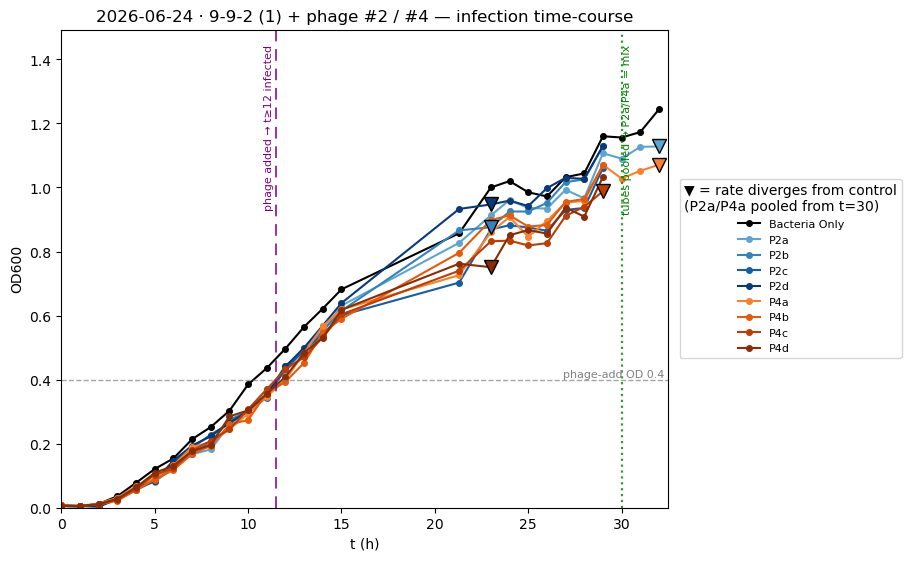

In [22]:
GROUP_CMAP = {"phage #2": plt.cm.Blues, "phage #4": plt.cm.Oranges}
DIVERGENCE_K = 2   # rate gap must exceed pre-phage baseline by K*sigma to flag infection
phage_cols = [s for s in SAMPLE_COLS if s != "Bacteria Only"]

# gap-safe per-hour growth rate = ΔOD / Δt between each tube's CONSECUTIVE ACTUAL readings,
# so skipped measurement sessions and off-grid timepoints (e.g. t=21.3) are handled correctly
d_sorted = data.sort_values("t")
rate_w = (d_sorted.assign(rate=d_sorted.groupby("sample")["od600"].diff()
                          / d_sorted.groupby("sample")["t"].diff())
                  .pivot(index="t", columns="sample", values="rate"))

# baseline: how far each tube's rate normally sits below control BEFORE phage (t <= 11),
# where all tubes grow alike — captures the ordinary scatter/offset
pre = rate_w[rate_w.index <= PHAGE_ADDED_AFTER_T]
gap_pre = pd.concat([pre["Bacteria Only"] - pre[c] for c in phage_cols]).dropna()
mu, sigma = gap_pre.mean(), gap_pre.std()
threshold = mu + DIVERGENCE_K * sigma if np.isfinite(sigma) and sigma > 0 else np.inf

# first post-addition reading where a tube's rate falls significantly below control.
# NB: the single ΔOD/Δt step straddling the pooling boundary (mix_from_t) compares the old
# replicate-a tube to the new pooled tube — a small discontinuity there is expected, not lysis.
post = rate_w[rate_w.index > PHAGE_ADDED_AFTER_T]
diverge_t = {}
for c in phage_cols:
    gap = post["Bacteria Only"] - post[c]
    flagged = gap.index[gap > threshold]
    if len(flagged):
        diverge_t[c] = float(flagged[0])

print(f"Infection-detection rule: control-tube DeltaOD-per-h gap > {threshold:.4f} "
      f"(baseline {mu:.4f} + {DIVERGENCE_K}*sigma {sigma:.4f}).")
print("Diverged from control at t (h): "
      + (", ".join(f"{k}={v:g}" for k, v in diverge_t.items())
         if diverge_t else "none yet"))

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
for _, meta in SAMPLES.iterrows():
    s = meta["sample"]
    sub = data[data["sample"] == s].sort_values("t")
    if sub.empty:
        continue
    color = "black" if meta["group"] == "control" else \
            GROUP_CMAP[meta["group"]](0.40 + 0.14 * meta["replicate"])
    ax.plot(sub["t"], sub["od600"], "-o", ms=4, color=color, label=s)
    t_div = diverge_t.get(s)
    if t_div is not None:
        od_div = sub.loc[sub["t"] == t_div, "od600"]
        if not od_div.empty:
            ax.plot(t_div, od_div.iloc[0], marker="v", ms=10, color=color,
                    markeredgecolor="k", zorder=5)

ax.axhline(PHAGE_THRESHOLD, ls="--", lw=1, color="grey", alpha=.7)
ax.set_xlabel("t (h)"); ax.set_ylabel("OD600")
ax.set_title("2026-06-24 · 9-9-2 (1) + phage #2 / #4 — infection time-course")
# autoscale to the data; the 0.4 line only enters view once cultures approach it
xmax = max((data["t"].max() + 0.5) if not data.empty else 24, 24)
ax.set_xlim(0, xmax)
top = max((data["od600"].max() * 1.2) if not data.empty else 0.45, 0.05)
ax.set_ylim(0, top)            # set last so axhline can't stretch the y-axis
if PHAGE_THRESHOLD <= top:
    ax.text(xmax, PHAGE_THRESHOLD, "phage-add OD 0.4 ", va="bottom", ha="right",
            fontsize=8, color="grey")
# phage added to all tubes after the t=11 reading → t>=12 is post-infection
ax.axvline(PHAGE_ADDED_AFTER_T + 0.5, ls=(0, (6, 4)), lw=1.4, color="purple", alpha=.8)
ax.text(PHAGE_ADDED_AFTER_T + 0.4, top * 0.97, "phage added → t≥12 infected",
        rotation=90, va="top", ha="right", fontsize=8, color="purple")
# tubes pooled: from here, P2a/P4a are mixes and the b/c/d curves end
mix_note = "▼ = rate diverges from control"
if mix_from_t is not None:
    ax.axvline(mix_from_t, ls=":", lw=1.6, color="green", alpha=.8)
    ax.text(mix_from_t, top * 0.97, "tubes pooled → P2a/P4a = mix",
            rotation=90, va="top", ha="left", fontsize=8, color="green")
    mix_note += f"\n(P2a/P4a pooled from t={mix_from_t:g})"
ax.legend(ncol=1, fontsize=8, title=mix_note,
          loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.savefig(OUT / "2026-06-24_od600_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 4 · Group means (control vs each phage)

Replicates averaged per group at each hour — the clean view of whether each phage collapses
the culture relative to the no-phage control.

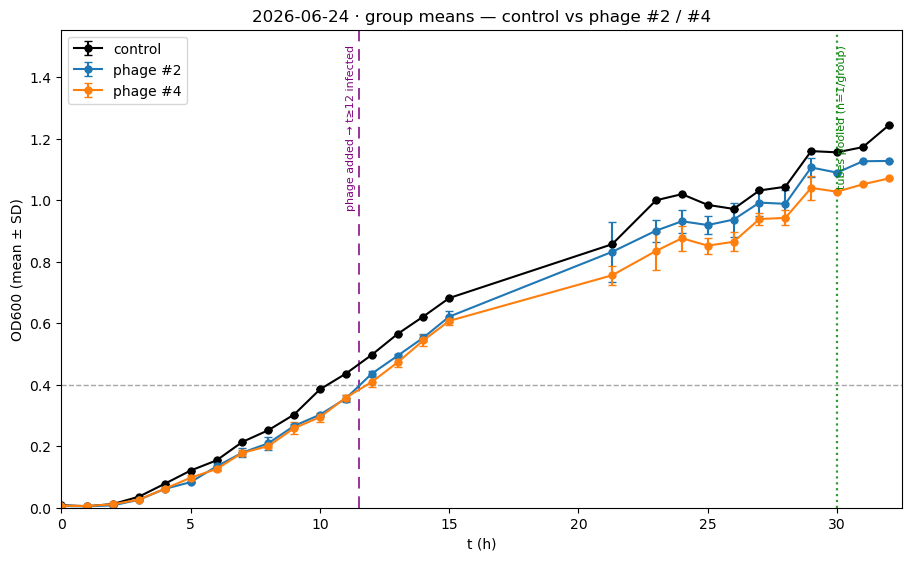

,group,t,mean,std,count
0,control,0.0,0.00800,NaN,1
1,control,1.0,0.00500,NaN,1
2,control,2.0,0.01200,NaN,1
3,control,3.0,0.03600,NaN,1
4,control,4.0,0.07800,NaN,1
...,...,...,...,...,...
76,phage #4,28.0,0.94275,0.024703,4
77,phage #4,29.0,1.04025,0.038965,4
78,phage #4,30.0,1.02800,NaN,1
79,phage #4,31.0,1.05200,NaN,1


In [23]:
if not data.empty:
    grp = (data.groupby(["group", "t"])["od600"]
               .agg(["mean", "std", "count"]).reset_index())
    fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
    colors = {"control": "black", "phage #2": "#1f77b4", "phage #4": "#ff7f0e"}
    for g, sub in grp.groupby("group"):
        ax.errorbar(sub["t"], sub["mean"], yerr=sub["std"].fillna(0),
                    marker="o", ms=5, capsize=3, color=colors.get(g), label=g)
    ax.axhline(PHAGE_THRESHOLD, ls="--", lw=1, color="grey", alpha=.7)
    ax.set_xlabel("t (h)"); ax.set_ylabel("OD600 (mean ± SD)")
    ax.set_title("2026-06-24 · group means — control vs phage #2 / #4")
    ax.set_xlim(0, max(grp["t"].max() + 0.5, 24))
    gtop = max(grp["mean"].max() * 1.25, 0.05)
    ax.set_ylim(0, gtop)
    ax.axvline(PHAGE_ADDED_AFTER_T + 0.5, ls=(0, (6, 4)), lw=1.4, color="purple", alpha=.8)
    ax.text(PHAGE_ADDED_AFTER_T + 0.4, gtop * 0.97, "phage added → t≥12 infected",
            rotation=90, va="top", ha="right", fontsize=8, color="purple")
    if mix_from_t is not None:
        # after pooling each phage group is one tube, so its "mean" is that single mix reading
        ax.axvline(mix_from_t, ls=":", lw=1.6, color="green", alpha=.8)
        ax.text(mix_from_t, gtop * 0.97, "tubes pooled (n=1/group)",
                rotation=90, va="top", ha="left", fontsize=8, color="green")
    ax.legend(loc="upper left")
    fig.savefig(OUT / "2026-06-24_od600_group-means.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(grp)
else:
    print("No readings yet — fill ../data/assays/0624_od600_phage.csv and re-run.")

## 5 · How long until the cultures reach OD 0.4?

Before phage is spiked in, every tube is the same growing culture, so we estimate the spike-in
time from the **average OD across all 9 tubes** (more robust than the single control well).
Only the **pre-phage readings (t ≤ 11)** are used here — phage was added after the t=11 reading.
Bacteria grow exponentially in log phase, so OD ≈ OD₀·e^(μt) and **ln(OD) is linear in t**.
We fit a line to the all-tube mean over its log-phase readings — points with OD in [0.02, 0.4)
(above lag-phase noise, below the spike-in target) — and extrapolate to OD = 0.4:

  t(0.4) = (ln 0.4 − intercept) / μ

Reports growth rate μ, doubling time (ln2/μ), R² of the fit, the predicted `t`, and the clock
time. **Caveat:** pure extrapolation — it assumes growth stays exponential; if the cultures
start to plateau before 0.4 the real time will be *later* than predicted.

Exponential fit on 9 all-tube-mean points (OD 0.027-0.365, t=3.0-11.0 h):
  growth rate mu = 0.295 /h   doubling time = 2.35 h   R2 = 0.9206
=> cultures predicted to reach OD 0.4 at t ~ 10.5 h  (~-0.5 h after the last reading at t=11.0; clock ~ 21:11).


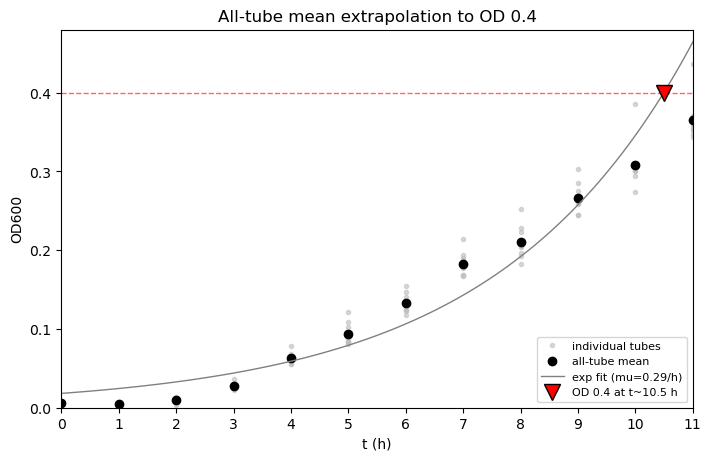

In [24]:
from datetime import datetime, timedelta
from matplotlib.ticker import MultipleLocator

EXP_MIN_OD = 0.02   # floor: ignore lag-phase / noise below this when fitting

# pre-phage growth only — phage was spiked in after t = PHAGE_ADDED_AFTER_T
pre = data[data["t"] <= PHAGE_ADDED_AFTER_T]
# mean OD across all tubes at each timepoint
avg = (pre.groupby("t")["od600"].mean()
          .reset_index(name="od600").sort_values("t").reset_index(drop=True))

if avg.empty:
    print("No readings yet.")
else:
    hit = avg[avg["od600"] >= PHAGE_THRESHOLD]
    fit = avg[(avg["od600"] >= EXP_MIN_OD) & (avg["od600"] < PHAGE_THRESHOLD)]
    if not hit.empty:
        print(f"All-tube mean has ALREADY reached OD {PHAGE_THRESHOLD} "
              f"at t = {hit['t'].iloc[0]} h (OD {hit['od600'].iloc[0]:.3f}).")
    elif len(fit) < 2:
        print(f"Need >=2 mean readings with OD in [{EXP_MIN_OD}, {PHAGE_THRESHOLD}) "
              f"to fit growth — have {len(fit)}. Keep logging and re-run.")
    else:
        slope, intercept = np.polyfit(fit["t"], np.log(fit["od600"]), 1)
        pred = slope * fit["t"] + intercept
        ln_od = np.log(fit["od600"])
        ss_tot = ((ln_od - ln_od.mean()) ** 2).sum()
        r2 = 1 - ((ln_od - pred) ** 2).sum() / ss_tot if ss_tot > 0 else float("nan")
        doubling = np.log(2) / slope if slope > 0 else float("inf")
        t_target = (np.log(PHAGE_THRESHOLD) - intercept) / slope
        t_last = avg["t"].max()

        # clock time: t is in hours measured from the t=0 reading
        eta_clock = "n/a"
        t0_row = wide.loc[wide["t"] == 0, "time"].dropna()
        if not t0_row.empty:
            try:
                eta_clock = (datetime.strptime(t0_row.iloc[0], "%H:%M")
                             + timedelta(hours=float(t_target))).strftime("%H:%M")
            except ValueError:
                pass

        print(f"Exponential fit on {len(fit)} all-tube-mean points "
              f"(OD {fit['od600'].min():.3f}-{fit['od600'].max():.3f}, "
              f"t={fit['t'].min()}-{fit['t'].max()} h):")
        print(f"  growth rate mu = {slope:.3f} /h   "
              f"doubling time = {doubling:.2f} h   R2 = {r2:.4f}")
        print(f"=> cultures predicted to reach OD {PHAGE_THRESHOLD} at "
              f"t ~ {t_target:.1f} h  (~{t_target - t_last:.1f} h after the last "
              f"reading at t={t_last}; clock ~ {eta_clock}).")

        fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
        ax.plot(pre["t"], pre["od600"], "o", ms=3, color="0.75", alpha=.6,
                label="individual tubes")
        ax.plot(avg["t"], avg["od600"], "o", color="black", label="all-tube mean")
        tt = np.linspace(0, max(t_target * 1.05, t_last), 100)
        ax.plot(tt, np.exp(slope * tt + intercept), "-", color="grey", lw=1,
                label=f"exp fit (mu={slope:.2f}/h)")
        ax.axhline(PHAGE_THRESHOLD, ls="--", lw=1, color="red", alpha=.6)
        ax.plot(t_target, PHAGE_THRESHOLD, "v", color="red", ms=11, markeredgecolor="k",
                zorder=5, label=f"OD 0.4 at t~{t_target:.1f} h")
        ax.set_xlabel("t (h)"); ax.set_ylabel("OD600")
        ax.set_ylim(0, PHAGE_THRESHOLD * 1.2)
        ax.set_xlim(0, PHAGE_ADDED_AFTER_T)   # pre-phage window; phage added after t=11
        ax.xaxis.set_major_locator(MultipleLocator(1))   # t ticks every 1 h
        ax.set_title("All-tube mean extrapolation to OD 0.4")
        ax.legend(fontsize=8)
        fig.savefig(OUT / "2026-06-24_control_eta_OD0.4.png", dpi=150, bbox_inches="tight")
        plt.show()